# M2.9 · 因子挖掘前沿

> 人工构造因子效率有限，自动化挖掘用公式因子库和机器学习/遗传规划批量搜索因子。
> 本节复现 Alpha101/191 精选因子，并用不依赖 gplearn 的自实现遗传规划（GP）自动挖掘，介绍前沿工具。

## 一、自动化挖掘路线

| 路线 | 代表 | 特点 |
|---|---|---|
| 公式因子库 | Alpha101、Alpha191、Alpha158 | 人工总结的批量表达式，可直接复现 |
| 遗传规划 | gplearn、自实现 GP | 表达式树交叉变异，按 IC 进化 |
| 强化学习 | AlphaGen | RL 生成因子表达式 |
| 自动化研发 | RD-Agent | LLM 驱动因子/模型自动生成与回测 |

本环境 gplearn 未装，用 L1 已验证的自实现 GP（factor_lab/mining.py），逻辑与 gplearn 一致。


## 二、加载数据并评估 Alpha101/191

In [1]:
import sys, numpy as np, pandas as pd
sys.path.insert(0, r'C:\Users\gucao\Desktop\Qlib')
import qlib
from qlib.data import D
from l2.config import load_universe
import config
from factor_lab2 import alphas
from factor_lab.evaluate import ic_series, ic_summary, fwd_returns
qlib.init(provider_uri=str(config.QLIB_DAILY_DIR), joblib_backend='threading')
codes = load_universe('hs300')
raw = D.features(codes, ['$open','$close','$high','$low','$volume',
                         '$mkt_cap_ard','$pe_ttm','$pb_lf'],
                 start_time='2018-01-01', freq='day')
op=raw['$open'].unstack('instrument'); cl=raw['$close'].unstack('instrument')
hi=raw['$high'].unstack('instrument'); lo=raw['$low'].unstack('instrument')
vo=raw['$volume'].unstack('instrument'); mk=raw['$mkt_cap_ard'].unstack('instrument')
pe=raw['$pe_ttm'].unstack('instrument'); pb=raw['$pb_lf'].unstack('instrument')
al = alphas.build_alphas(op, cl, vo, hi, lo)
fwd1 = fwd_returns(cl,1)
arows = []
for n, fac in al.items():
    arows.append({'因子':n,'IC':ic_summary(ic_series(fac,fwd1))['IC均值']})
atbl = pd.DataFrame(arows).set_index('因子').sort_values('IC')
print(atbl.round(4).to_string())

[27676:MainThread](2026-11-05 16:38:17,265) INFO - qlib.Initialization - [config.py:452] - default_conf: client.


[27676:MainThread](2026-11-05 16:38:19,298) INFO - qlib.Initialization - [__init__.py:75] - qlib successfully initialized based on client settings.


[27676:MainThread](2026-11-05 16:38:19,300) INFO - qlib.Initialization - [__init__.py:77] - data_path={'__DEFAULT_FREQ': WindowsPath('C:/Users/gucao/Desktop/Qlib/data/qlib_daily')}


                   IC
因子                   
Alpha191#3    -0.0012
Alpha191#1     0.0057
Alpha191 振幅反转  0.0078
Alpha101#12    0.0082
Alpha101#6     0.0105
Alpha101 反转变体  0.0210


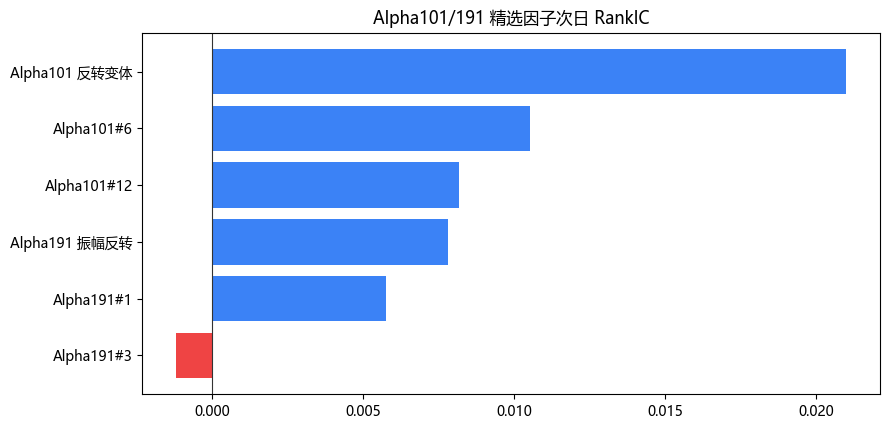

In [2]:
import matplotlib.pyplot as plt
plt.rcParams['font.sans-serif'] = ['Microsoft YaHei']
plt.rcParams['axes.unicode_minus'] = False
fig, ax = plt.subplots(figsize=(9,4.4))
colors = ['#ef4444' if x<0 else '#3b82f6' for x in atbl['IC']]
ax.barh(atbl.index, atbl['IC'], color=colors)
ax.axvline(0, color='#333', lw=0.8)
ax.set_title('Alpha101/191 精选因子次日 RankIC')
plt.tight_layout(); plt.show()

## 三、自实现遗传规划（GP）自动挖掘

### 原理
- 因子表示为表达式树（算子+叶子因子），如 `ts_mean10(ret20)`；
- 种群随机生成，按 |IC| 评估适应度，通过交叉、变异进化，保留精英；
- 多代后选出 IC 最高的因子表达式。


In [3]:
from factor_lab import mining
base = mining.make_base(cl, vo, mk, pe, pb)
fwd5 = fwd_returns(cl, 5)
# 小规模演示（可加大种群/代数），固定种子保证可复现
scored, history = mining.run_gp(base, fwd5, n_pop=40, n_gen=6,
                                n_elite=6, sample_step=5, seed=42,
                                max_depth=3, verbose=True)
print('每代最优 |IC|:', [round(h,4) for h in history])

C:\Users\gucao\.conda\envs\qlib\lib\site-packages\pandas\core\nanops.py:1632: ConstantInputWarning: An input array is constant; the correlation coefficient is not defined.
  return spearmanr(a, b)[0]


第0代 最优|IC|=0.0185


C:\Users\gucao\.conda\envs\qlib\lib\site-packages\pandas\core\nanops.py:1632: ConstantInputWarning: An input array is constant; the correlation coefficient is not defined.
  return spearmanr(a, b)[0]


C:\Users\gucao\.conda\envs\qlib\lib\site-packages\pandas\core\nanops.py:1632: ConstantInputWarning: An input array is constant; the correlation coefficient is not defined.
  return spearmanr(a, b)[0]


C:\Users\gucao\.conda\envs\qlib\lib\site-packages\pandas\core\nanops.py:1632: ConstantInputWarning: An input array is constant; the correlation coefficient is not defined.
  return spearmanr(a, b)[0]


第1代 最优|IC|=0.0195


C:\Users\gucao\.conda\envs\qlib\lib\site-packages\pandas\core\nanops.py:1632: ConstantInputWarning: An input array is constant; the correlation coefficient is not defined.
  return spearmanr(a, b)[0]


第2代 最优|IC|=0.0210


第3代 最优|IC|=0.0228


第4代 最优|IC|=0.0257


第5代 最优|IC|=0.0257
每代最优 |IC|: [np.float64(0.0185), np.float64(0.0195), np.float64(0.021), np.float64(0.0228), np.float64(0.0257), np.float64(0.0257)]


In [4]:
# 最优因子
best = scored[0]
print('最优表达式:', mining.expr_to_str(best[2]))
print('最优 |IC|=%.4f, 方向IC=%.4f' % (best[0], best[1]))

最优表达式: ts_mean10(ts_max10(ts_max10(ret20)))
最优 |IC|=0.0257, 方向IC=-0.0257


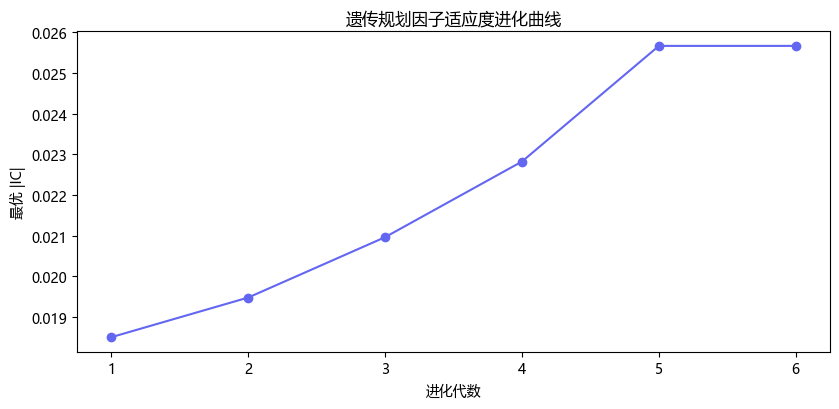

In [5]:
fig, ax = plt.subplots(figsize=(8.5,4.2))
ax.plot(range(1,len(history)+1), history, 'o-', color='#6366f1')
ax.set_xlabel('进化代数'); ax.set_ylabel('最优 |IC|')
ax.set_title('遗传规划因子适应度进化曲线')
plt.tight_layout(); plt.show()

## 四、前沿工具与注意事项

- **gplearn**：成熟的符号回归/GP 库，算子可自定义；本项目自实现 GP 与其等价。
- **AlphaGen**：用强化学习（PPO）直接生成因子表达式，奖励结合 IC 和风险。
- **RD-Agent**：微软开源，LLM 自动提出因子假设、生成代码、回测、迭代。
- **风险提示**：自动挖掘极易过拟合，需样本外验证、控制因子数量、考虑相关性和成本，避免数据挖掘偏差。

## 五、小结与面试要点

- 自动化挖掘：公式因子库可直接复现，GP 用表达式树进化，RL/LLM 是新方向。
- 核心不是挖出高 IC，而是样本外稳健、低相关、可交易。

**面试高频：**
- 遗传规划怎么挖因子？（答：表达式树种群，按IC适应度，交叉变异，精英保留迭代）
- 自动挖因子最大的风险？（答：过拟合/数据挖掘偏差，需样本外、多重检验校正）
- 怎么防止挖掘出一堆高相关因子？（答：正交、相关过滤、按因子簇去重）
- AlphaGen 和 GP 有什么不同？（答：AlphaGen用强化学习序列生成，GP用进化搜索）

## 动手练习
1. 复现并评估 Alpha101/191 因子；
2. 运行自实现 GP，观察进化曲线和最优表达式；
3. 对挖出的因子做样本外验证，判断是否稳健。

---
**M2 因子进阶（下）全部完成，B3 收尾。** 至此因子模块（M2）九个 notebook 全部交付。